<a href="https://colab.research.google.com/github/MohamedAazir/EN4554_A2/blob/main/EN4554_A2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2 – CNNs
Aazir M.A.M. - 220005R  
**GitHub:** https://github.com/MohamedAazir/EN4554_A2/

**Tool acknowledgement:** I used Claude to help with the assignment. I have read and understood all of it and can explain it.

## Setup
CIFAR-10, 45k train / 5k validation split, per-channel normalisation using training statistics only, fixed seeds. The test set is loaded only once, in Task 4.

In [ ]:
import random, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision

In [2]:
def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

full = torchvision.datasets.CIFAR10('./data', train=True, download=True)
X = torch.tensor(full.data).permute(0, 3, 1, 2).float() / 255      # (50000,3,32,32)
Y = torch.tensor(full.targets)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, Ytr, Xva, Yva = X[tr_idx], Y[tr_idx], X[va_idx], Y[va_idx]

mean = Xtr.mean((0, 2, 3), keepdim=True)      # statistics from the training split only
std  = Xtr.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr - mean) / std).to(device); Ytr = Ytr.to(device)
Xva = ((Xva - mean) / std).to(device); Yva = Yva.to(device)
print(Xtr.shape, Xva.shape)

device: cuda


100%|██████████| 170M/170M [36:17<00:00, 78.3kB/s]


torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])



### Common helpers (batching on GPU, evaluation, a generic training loop, small CNN)


In [9]:
def batches(X, Y, bs, shuffle=True, aug=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        x, y = X[j], Y[j]
        if aug is not None: x = aug(x)
        yield x, y

@torch.no_grad()
def evaluate(model, X, Y, bs=1000):
    model.eval(); loss = 0; correct = 0
    for x, y in batches(X, Y, bs, shuffle=False):
        out = model(x)
        loss += F.cross_entropy(out, y, reduction='sum').item()
        correct += (out.argmax(1) == y).sum().item()
    return loss / len(X), correct / len(X)

def train(model, opt, epochs, Xt, Yt, Xv, Yv, bs=128, aug=None, mix=False, sched=None):
    """Returns per-epoch training loss, train accuracy (clean, eval mode, <=5000 imgs) and validation accuracy."""
    h = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(epochs):
        model.train(); tot = 0; n = 0
        for x, y in batches(Xt, Yt, bs, aug=aug):
            if mix:
                x, ya, yb, lam = mixup(x, y)
                out = model(x)
                loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb)
            else:
                out = model(x); loss = F.cross_entropy(out, y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x); n += len(x)
        if sched is not None: sched.step()
        h['train_loss'].append(tot / n)
        h['train_acc'].append(evaluate(model, Xt[:5000], Yt[:5000])[1])
        h['val_acc'].append(evaluate(model, Xv, Yv)[1])
        if (ep + 1) % 5 == 0 or ep == 0:
          print(f"ep {ep+1:3d}  loss {h['train_loss'][-1]:.3f}  train {h['train_acc'][-1]:.3f}  val {h['val_acc'][-1]:.3f}")
    return h

def small_cnn(bn=True, p_drop=0.0):
    def blk(i, o):
        return [nn.Conv2d(i, o, 3, padding=1, bias=not bn)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128),
                         nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 10)).to(device)

# Task 1: Backpropagation

### (a) Linear, ReLU, softmax cross-entropy with explicit forward/backward, and an MLP
No autograd is used. `SoftmaxCE.backward` uses the identity dL/dlogits = (softmax − onehot)/N.

In [10]:
class Linear:
    def __init__(self, din, dout, dtype=torch.float32, dev=device):
        self.W = torch.randn(din, dout, dtype=dtype, device=dev) * (2 / din) ** 0.5
        self.b = torch.zeros(dout, dtype=dtype, device=dev)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values          # numerical stability
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        self.idx = torch.arange(len(y), device=y.device)
        return -logp[self.idx, y].mean()
    def backward(self):
        g = self.p.clone()
        g[self.idx, self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU, dtype=torch.float32, dev=device):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], dtype, dev))
            if i < len(sizes) - 2: self.layers.append(act())
        self.loss_fn = SoftmaxCE()
    def logits(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def forward(self, x, y):                 # returns the loss
        return self.loss_fn.forward(self.logits(x), y)
    def backward(self):
        g = self.loss_fn.backward()
        for l in reversed(self.layers): g = l.backward(g)
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]
    def sgd_step(self, lr):
        for l in self.linears():
            l.W -= lr * l.dW; l.b -= lr * l.db

### (b) Gradient check against autograd and centred finite differences
Finite differences use 5 randomly chosen entries per parameter tensor (checking all 3072×64 weights would be very slow).

In [11]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def fd_grad(net, xb, yb, p, idxs, eps=1e-5):
    flat = p.view(-1); out = []
    for k in idxs:
        old = flat[k].item()
        flat[k] = old + eps; lp = net.forward(xb, yb).item()
        flat[k] = old - eps; lm = net.forward(xb, yb).item()
        flat[k] = old
        out.append((lp - lm) / (2 * eps))
    return torch.tensor(out, dtype=torch.float64)

set_seed(1)
xb = Xtr[:16].flatten(1).cpu().double(); yb = Ytr[:16].cpu()
net = MLP([3072, 64, 32, 10], dtype=torch.float64, dev='cpu')
net.forward(xb, yb); net.backward()

params = []                                               # (name, parameter, our gradient)
for i, l in enumerate(net.linears()):
    params += [(f'L{i}.W', l.W, l.dW), (f'L{i}.b', l.b, l.db)]

# autograd reference with identical weights
ps = [p.clone().requires_grad_() for _, p, _ in params]
h = xb
for i in range(0, len(ps), 2):
    h = h @ ps[i] + ps[i + 1]
    if i < len(ps) - 2: h = F.relu(h)
F.cross_entropy(h, yb).backward()

rows = []
for (name, p, g), q in zip(params, ps):
    idxs = torch.randint(0, p.numel(), (5,))
    fd = fd_grad(net, xb, yb, p, idxs)
    rows.append({'param': name,
                 'rel.err vs autograd': rel_err(g, q.grad),
                 'allclose(autograd)': torch.allclose(g, q.grad),
                 'rel.err vs finite diff': rel_err(g.view(-1)[idxs], fd)})
pd.DataFrame(rows).style.format({'rel.err vs autograd': '{:.2e}', 'rel.err vs finite diff': '{:.2e}'})

,param,rel.err vs autograd,allclose(autograd),rel.err vs finite diff
0,L0.W,8.02e-17,True,1.53e-10
1,L0.b,8.09e-17,True,7.94e-11
2,L1.W,5.77e-17,True,2.05e-10
3,L1.b,4.65e-17,True,3.10e-10
4,L2.W,4.77e-17,True,9.02e-11
5,L2.b,8.79e-17,True,1.82e-10


**Interpretation:** The hand-written gradients match autograd almost exactly. Relative errors are about 5e-17 to 9e-17 for every weight and bias, and `torch.allclose` returns `True` for all six parameter tensors, so the backward passes of Linear, ReLU and softmax cross-entropy are correct. The centred finite-difference errors are larger (8e-11 to 3e-10) because finite differences carry an O(ε²) truncation error plus round-off, but they are still tiny. They confirm the analytic gradients independently of autograd.

---



### (c) Train the MLP with SGD on flattened CIFAR-10

epoch 1: val acc 0.443
epoch 2: val acc 0.461
epoch 3: val acc 0.458
epoch 4: val acc 0.488
epoch 5: val acc 0.497
epoch 6: val acc 0.498
epoch 7: val acc 0.501
epoch 8: val acc 0.501
epoch 9: val acc 0.503
epoch 10: val acc 0.498
epoch 11: val acc 0.495
epoch 12: val acc 0.498
epoch 13: val acc 0.501
epoch 14: val acc 0.501
epoch 15: val acc 0.505
epoch 16: val acc 0.478
epoch 17: val acc 0.498
epoch 18: val acc 0.497
epoch 19: val acc 0.498
epoch 20: val acc 0.497
epoch 21: val acc 0.521
epoch 22: val acc 0.524
epoch 23: val acc 0.521
epoch 24: val acc 0.521
epoch 25: val acc 0.522
epoch 26: val acc 0.522
epoch 27: val acc 0.523
epoch 28: val acc 0.526
epoch 29: val acc 0.524
epoch 30: val acc 0.524


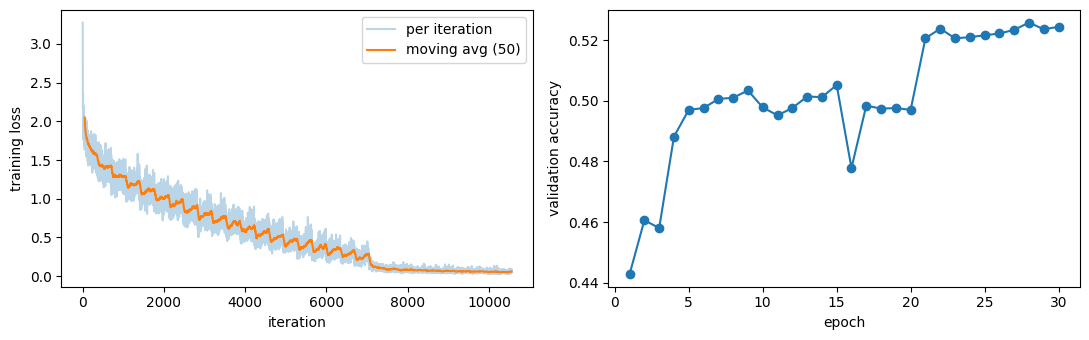

final validation accuracy: 0.524399995803833


In [12]:
set_seed(0)
Xtr_f, Xva_f = Xtr.flatten(1), Xva.flatten(1)
mlp = MLP([3072, 512, 256, 10])
losses, val_accs = [], []
for ep in range(30):
    lr = 0.05 if ep < 20 else 0.01
    for x, y in batches(Xtr_f, Ytr, 128):
        loss = mlp.forward(x, y); mlp.backward(); mlp.sgd_step(lr)
        losses.append(loss.item())
    acc = (mlp.logits(Xva_f).argmax(1) == Yva).float().mean().item()
    val_accs.append(acc); print(f'epoch {ep+1}: val acc {acc:.3f}')

sm = np.convolve(losses, np.ones(50) / 50, mode='valid')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=.3, label='per iteration'); ax[0].plot(np.arange(len(sm)) + 49, sm, label='moving avg (50)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('training loss'); ax[0].legend()
ax[1].plot(range(1, 31), val_accs, 'o-'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy')
plt.tight_layout(); plt.show()
print('final validation accuracy:', val_accs[-1])

**Interpretation:** The training loss drops quickly from about 3.3 in the first iterations (chance level is ln 10 ≈ 2.3) to about 0.05 by the end, so the MLP essentially memorises the training set. Validation accuracy is much lower: it plateaus at about 50% for epochs 5–20 and rises to 52.4% after the learning rate is reduced at epoch 20. The large gap between near-zero training loss and 52% validation accuracy shows strong overfitting. A fully connected network on flattened pixels ignores image structure and has no translation invariance, which is why it cannot generalise well and why CNNs are used.

### (d) Per-layer gradient norm at initialisation, 10-layer MLP: sigmoid vs ReLU
Same width (256), same He initialisation, same batch; only the activation differs. Layer 1 is next to the input, layer 10 next to the loss.

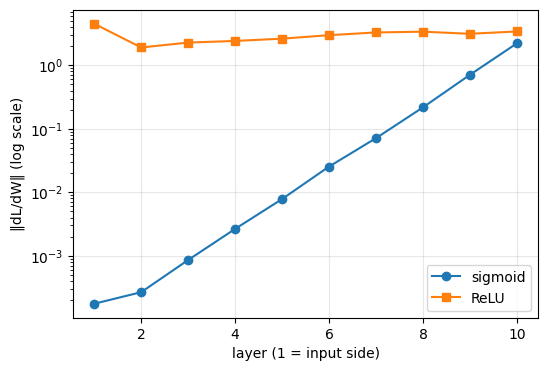

sigmoid  layer1/layer10 ratio: 7.871915329906275e-05
ReLU     layer1/layer10 ratio: 1.3241704606120042


In [13]:
def layer_grad_norms(act):
    set_seed(0)
    net = MLP([3072] + [256] * 9 + [10], act=act)          # 10 Linear layers
    net.forward(Xtr_f[:256], Ytr[:256]); net.backward()
    return [l.dW.norm().item() for l in net.linears()]

g_sig, g_relu = layer_grad_norms(Sigmoid), layer_grad_norms(ReLU)
plt.figure(figsize=(6, 4))
plt.semilogy(range(1, 11), g_sig, 'o-', label='sigmoid')
plt.semilogy(range(1, 11), g_relu, 's-', label='ReLU')
plt.xlabel('layer (1 = input side)'); plt.ylabel('‖dL/dW‖ (log scale)'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('sigmoid  layer1/layer10 ratio:', g_sig[0] / g_sig[-1])
print('ReLU     layer1/layer10 ratio:', g_relu[0] / g_relu[-1])

**Interpretation:** With sigmoid, the gradient norm shrinks by orders of magnitude from the output layer to the input layer. The layer-1 to layer-10 ratio is 7.9×10⁻⁵, which is vanishing gradients. The sigmoid derivative is at most 0.25, so each layer multiplies the backward signal by a small factor and the product over 10 layers becomes tiny. The early layers would therefore learn very slowly. With ReLU the ratio is 1.32, so the norms stay in the same range across all layers. The ReLU derivative is exactly 1 for active units, and He initialisation keeps the signal variance roughly constant.

# Task 2: Optimizers

### (a) SGD with momentum and Adam (with bias correction) as `torch.optim.Optimizer` subclasses

In [14]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad
                if group['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = g.clone()
                    else: st['buf'].mul_(group['momentum']).add_(g)     # v = mu*v + g
                    g = st['buf']
                p.add_(g, alpha=-group['lr'])                          # p = p - lr*v

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad; st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1
                st['m'].mul_(b1).add_(g, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = st['m'] / (1 - b1 ** st['t'])                  # bias correction
                v_hat = st['v'] / (1 - b2 ** st['t'])
                p.addcdiv_(m_hat, v_hat.sqrt() + group['eps'], value=-group['lr'])

In [15]:
def compare(my_cls, ref_cls, steps=50, **kw):
    set_seed(0)
    m1 = nn.Linear(10, 5).double(); m2 = nn.Linear(10, 5).double(); m2.load_state_dict(m1.state_dict())
    o1, o2 = my_cls(m1.parameters(), **kw), ref_cls(m2.parameters(), **kw)
    x, t = torch.randn(32, 10).double(), torch.randn(32, 5).double()
    for _ in range(steps):
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); F.mse_loss(m(x), t).backward(); o.step()
    diff = max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(a, b) for a, b in zip(m1.parameters(), m2.parameters()))
    return ok, diff

for name, mine, ref, kw in [('SGD (no momentum)', MySGD, torch.optim.SGD, dict(lr=0.05)),
                            ('SGD + momentum', MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
                            ('Adam', MyAdam, torch.optim.Adam, dict(lr=1e-2))]:
    ok, d = compare(mine, ref, **kw)
    print(f'{name:18s} allclose: {ok}   max |diff| = {d:.2e}')

SGD (no momentum)  allclose: True   max |diff| = 0.00e+00
SGD + momentum     allclose: True   max |diff| = 0.00e+00
Adam               allclose: True   max |diff| = 1.11e-16


**Interpretation:** After 50 update steps, my SGD and SGD-with-momentum optimizers give parameters identical to `torch.optim.SGD` (max difference 0), and my Adam differs from `torch.optim.Adam` by only 1.1×10⁻¹⁶, which is float64 round-off. All comparisons are `allclose = True`, so the update rules, including Adam’s bias correction, are implemented correctly.

### (b) Trajectories on f(x, y) = ½(x² + 50y²)
Condition number = 50. Step sizes: SGD lr 0.035 (stability limit is 2/50 = 0.04), momentum lr 0.02 with β = 0.9, Adam lr 0.3. Start at (10, 1).

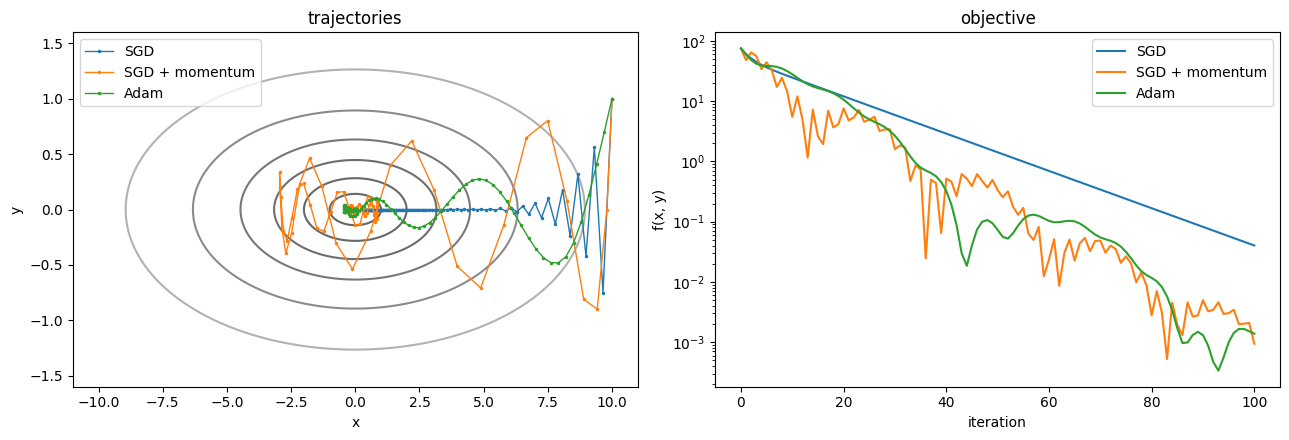

In [16]:
def run(opt_cls, steps=100, **kw):
    p = torch.tensor([10., 1.], requires_grad=True)
    opt = opt_cls([p], **kw); path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad(); (0.5 * (p[0] ** 2 + 50 * p[1] ** 2)).backward(); opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

paths = {'SGD': run(MySGD, lr=0.035),
         'SGD + momentum': run(MySGD, lr=0.02, momentum=0.9),
         'Adam': run(MyAdam, lr=0.3)}

xs, ys = np.meshgrid(np.linspace(-11, 11, 400), np.linspace(-1.6, 1.6, 400))
zs = 0.5 * (xs ** 2 + 50 * ys ** 2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(xs, ys, zs, levels=[0.5, 2, 5, 10, 20, 40, 80], cmap='gray', alpha=.6)
for name, pth in paths.items():
    ax[0].plot(pth[:, 0], pth[:, 1], '.-', ms=3, lw=1, label=name)
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title('trajectories'); ax[0].legend()
for name, pth in paths.items():
    ax[1].semilogy(0.5 * (pth[:, 0] ** 2 + 50 * pth[:, 1] ** 2) + 1e-12, label=name)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('f(x, y)'); ax[1].set_title('objective'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation:** The contours are very elongated, the function is steep in y and shallow in x (condition number 50). Plain SGD must use a step small enough for the steep y direction. It zig-zags across the valley for the first few steps, then settles on y = 0 and creeps slowly along x, so its objective falls smoothly but slowly (about 4×10⁻² after 100 steps). SGD with momentum accumulates the consistent gradient along x, so it makes much faster progress, reaching about 10⁻³. However, it overshoots and oscillates widely in both x and y, so its objective curve is jagged. Adam normalises each coordinate by its own gradient scale, which reduces the 50× difference between the axes. It follows a smooth, damped oscillating path and also reaches about 10⁻³, with small oscillations remaining near the minimum because its step size stays close to the learning rate. Both momentum and Adam therefore beat plain SGD on this ill-conditioned problem, in different ways.

### (c) Small CNN with each optimizer at three learning rates
Small CNN without batch norm (so that learning-rate sensitivity is visible), 8 epochs, full 45k training split. Compared by final validation accuracy.

In [19]:
EPOCHS_2C = 15
grid = {'SGD':          (MySGD,  dict(),             [0.03, 0.1, 0.3]),
        'SGD+momentum': (MySGD,  dict(momentum=0.9), [0.001, 0.01, 0.1]),
        'Adam':         (MyAdam, dict(),             [1e-4, 1e-3, 1e-2])}
res2c = {}
for name, (cls, kw, lrs) in grid.items():
    for lr in lrs:
        print(f'--- {name}, lr={lr}')
        set_seed(0)
        model = small_cnn(bn=False)
        res2c[(name, lr)] = train(model, cls(model.parameters(), lr=lr, **kw), EPOCHS_2C, Xtr, Ytr, Xva, Yva)

--- SGD, lr=0.03
ep   1  loss 1.878  train 0.418  val 0.414
ep   5  loss 1.079  train 0.644  val 0.629
ep  10  loss 0.793  train 0.743  val 0.695
ep  15  loss 0.625  train 0.803  val 0.721
--- SGD, lr=0.1
ep   1  loss 1.677  train 0.507  val 0.500
ep   5  loss 0.803  train 0.748  val 0.702
ep  10  loss 0.495  train 0.839  val 0.719
ep  15  loss 0.293  train 0.879  val 0.713
--- SGD, lr=0.3
ep   1  loss 1.743  train 0.468  val 0.467
ep   5  loss 0.765  train 0.700  val 0.637
ep  10  loss 0.501  train 0.823  val 0.679
ep  15  loss 0.421  train 0.838  val 0.678
--- SGD+momentum, lr=0.001
ep   1  loss 2.122  train 0.302  val 0.303
ep   5  loss 1.363  train 0.524  val 0.520
ep  10  loss 1.096  train 0.621  val 0.603
ep  15  loss 0.938  train 0.682  val 0.659
--- SGD+momentum, lr=0.01
ep   1  loss 1.611  train 0.564  val 0.554
ep   5  loss 0.740  train 0.769  val 0.708
ep  10  loss 0.445  train 0.854  val 0.727
ep  15  loss 0.255  train 0.929  val 0.734
--- SGD+momentum, lr=0.1
ep   1  loss 

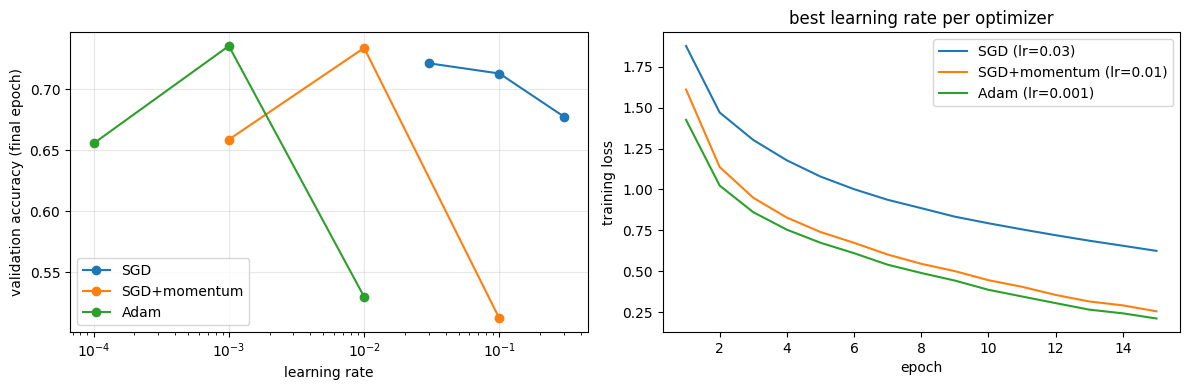

,optimizer,lr,final val acc,final train loss
0,SGD,0.0300,0.7214,0.624677
1,SGD,0.1000,0.7130,0.292673
2,SGD,0.3000,0.6776,0.420569
3,SGD+momentum,0.0010,0.6588,0.938291
4,SGD+momentum,0.0100,0.7340,0.255160
5,SGD+momentum,0.1000,0.5120,1.165263
6,Adam,0.0001,0.6556,0.921748
7,Adam,0.0010,0.7356,0.211205
8,Adam,0.0100,0.5298,1.213933


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for name, (_, _, lrs) in grid.items():
    accs = [res2c[(name, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name)
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel('learning rate'); ax[0].set_ylabel('validation accuracy (final epoch)'); ax[0].legend(); ax[0].grid(alpha=.3)
for name, lr in best.items():
    ax[1].plot(range(1, EPOCHS_2C + 1), res2c[(name, lr)]['train_loss'], label=f'{name} (lr={lr})')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss'); ax[1].set_title('best learning rate per optimizer'); ax[1].legend()
plt.tight_layout(); plt.show()
rows = [{'optimizer': k, 'lr': lr, 'final val acc': res2c[(k, lr)]['val_acc'][-1],
         'final train loss': res2c[(k, lr)]['train_loss'][-1]} for k, v in grid.items() for lr in v[2]]
pd.DataFrame(rows)

**Interpretation:** Validation accuracy depends strongly on the learning rate, with an inverted-U shape for SGD with momentum and Adam. Adam peaks at 73.6% (lr = 1e-3) and momentum at 73.4% (lr = 0.01). Both fall sharply on either side: at the small rates (1e-4 and 1e-3) they are too slow for 15 epochs (65.6% and 65.9%), and at the large rates (0.01 for Adam, 0.1 for momentum) they become unstable and fall to 53.0% and 51.2%. Momentum behaves like a learning rate about 10× larger (1/(1−β)), which is why its best rate is smaller than plain SGD’s. Adam moves every weight by about lr per step, which is too large at 0.01 for a network without batch norm. Plain SGD is the least sensitive over its grid (72.1%, 71.3%, 67.8% for 0.03, 0.1, 0.3), though its training loss falls the most slowly (0.62 at its best rate, against 0.26 for momentum and 0.21 for Adam after 15 epochs). The train/validation gap at the best rates (about 94% vs 73.6% for Adam) shows that this CNN overfits, since it has no augmentation or batch norm. In summary, the learning rate must be tuned separately for each optimizer, and Adam and momentum reach the best accuracy but only in a narrow range.

# Task 3: Regularisation and residual connections

### (a) Small CNN with batch norm on 5k training images
Cutout and mixup are implemented below. Flip + crop (pad 4, random 32×32 crop) is also done on the GPU. Weight decay 5e-4, dropout 0.5 before the classifier, cutout 16×16, mixup α = 1. SGD (momentum 0.9, lr 0.05), 30 epochs.

In [21]:
def flip_crop(x, pad=4):
    N = x.size(0)
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)           # random horizontal flip
    xp = F.pad(x, (pad,) * 4)                                          # zero padding
    i = torch.randint(0, 2 * pad + 1, (N,)); j = torch.randint(0, 2 * pad + 1, (N,))
    return torch.stack([xp[n, :, i[n]:i[n] + 32, j[n]:j[n] + 32] for n in range(N)])

def cutout(x, size=16):
    N, _, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device); cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]; xs = torch.arange(W, device=x.device)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole)[:, None].to(x.dtype)                           # zero (= mean colour) inside the square

def mixup(x, y, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam               # loss = lam*CE(y_a) + (1-lam)*CE(y_b)

In [22]:
EPOCHS_3A = 100
Xs, Ys = Xtr[:5000], Ytr[:5000]
aug_cut = lambda x: cutout(x, 8)                      # 8x8 hole suits 32x32 images with only 5k samples
both    = lambda x: cutout(flip_crop(x), 8)
cfgs = {'baseline': {}, 'weight decay': dict(wd=2e-3), 'dropout': dict(drop=0.5),
        'flip+crop': dict(aug=flip_crop), 'cutout': dict(aug=aug_cut), 'mixup': dict(mix=True),
        'all combined': dict(wd=2e-3, drop=0.5, aug=both, mix=True)}
res3a = {}
for name, c in cfgs.items():
    print(f'--- {name}')
    set_seed(0)
    model = small_cnn(bn=True, p_drop=c.get('drop', 0.0))
    opt = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=c.get('wd', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_3A)
    res3a[name] = train(model, opt, EPOCHS_3A, Xs, Ys, Xva, Yva,
                        aug=c.get('aug'), mix=c.get('mix', False), sched=sched)

--- baseline
ep   1  loss 2.043  train 0.385  val 0.351
ep   5  loss 0.997  train 0.707  val 0.550
ep  10  loss 0.435  train 0.876  val 0.601
ep  15  loss 0.153  train 0.966  val 0.598
ep  20  loss 0.042  train 1.000  val 0.638
ep  25  loss 0.022  train 1.000  val 0.638
ep  30  loss 0.013  train 1.000  val 0.639
ep  35  loss 0.008  train 1.000  val 0.642
ep  40  loss 0.008  train 1.000  val 0.642
ep  45  loss 0.014  train 1.000  val 0.641
ep  50  loss 0.006  train 1.000  val 0.643
ep  55  loss 0.014  train 1.000  val 0.632
ep  60  loss 0.005  train 1.000  val 0.642
ep  65  loss 0.005  train 1.000  val 0.639
ep  70  loss 0.005  train 1.000  val 0.643
ep  75  loss 0.004  train 1.000  val 0.641
ep  80  loss 0.004  train 1.000  val 0.644
ep  85  loss 0.004  train 1.000  val 0.643
ep  90  loss 0.004  train 1.000  val 0.639
ep  95  loss 0.004  train 1.000  val 0.642
ep 100  loss 0.004  train 1.000  val 0.641
--- weight decay
ep   1  loss 2.040  train 0.374  val 0.338
ep   5  loss 0.999  trai

,train acc (%),val acc (%),gap (%)
baseline,100.00,64.10,35.90
weight decay,100.00,65.20,34.80
dropout,100.00,69.12,30.88
flip+crop,93.82,73.86,19.96
cutout,100.00,66.00,34.00
mixup,100.00,61.62,38.38
all combined,74.72,68.14,6.58


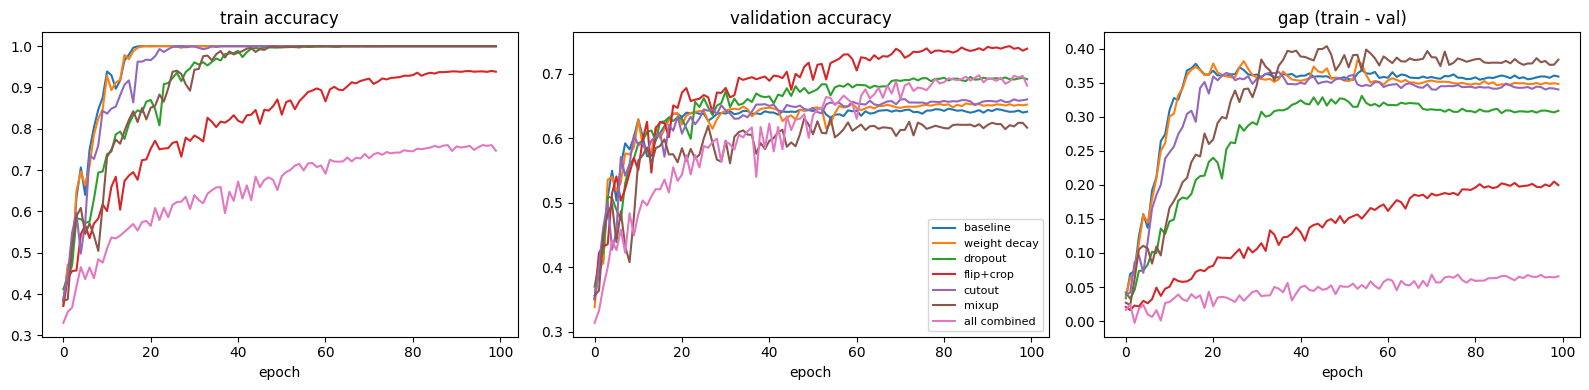

In [23]:
tab = pd.DataFrame({n: {'train acc (%)': 100 * h['train_acc'][-1], 'val acc (%)': 100 * h['val_acc'][-1],
                        'gap (%)': 100 * (h['train_acc'][-1] - h['val_acc'][-1])} for n, h in res3a.items()}).T
display(tab.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n, h in res3a.items():
    ax[0].plot(h['train_acc'], label=n); ax[1].plot(h['val_acc'], label=n)
    ax[2].plot(np.array(h['train_acc']) - np.array(h['val_acc']), label=n)
for a, t in zip(ax, ['train accuracy', 'validation accuracy', 'gap (train - val)']):
    a.set_title(t); a.set_xlabel('epoch')
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation:** With only 5k images the baseline memorises the training set (100% train accuracy) but reaches only 64.1% validation accuracy, a gap of 35.9 points. Weight decay (65.2%) and cutout (66.0%) give small gains, and dropout helps more (69.1%), but all of them still reach 100% training accuracy, so they only partly reduce the overfitting. Flip+crop is by far the best single method (73.9% validation, gap 20.0), because it adds new, label-preserving variation to the images. Mixup (61.6%) did not help here and was slightly worse than the baseline, probably because mixed images make the 5k-image task harder to fit within 100 epochs. Combining everything gives the smallest gap (6.6) and the lowest training accuracy (74.7%), but its validation accuracy (68.1%) is below flip+crop alone. The combined model is still under-trained and was improving when training stopped, so the regularisers together were too strong for this budget. The lesson is that augmentation that matches the data (flips and shifts) is the most effective regulariser, and stacking more of them is not always better.

### (b) Plain vs residual networks, depth 6n+2 = 8, 20, 56
Three stages (16/32/64 channels), global average pooling, batch norm, Kaiming initialisation. The only difference between the two families is the shortcut (`residual=False` simply skips the addition). No data augmentation here, so that the training loss reflects optimisation. SGD momentum 0.9, lr 0.05, 15 epochs.

In [24]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);    self.b2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.short = nn.Identity()
        if residual and (stride != 1 or cin != cout):                  # 1x1 projection when the shape changes
            self.short = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)))
        out = self.b2(self.c2(out))
        if self.residual: out = out + self.short(x)
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, residual, widths=(16, 32, 64)):
        super().__init__()
        self.conv = nn.Conv2d(3, widths[0], 3, padding=1, bias=False); self.bn = nn.BatchNorm2d(widths[0])
        layers, cin = [], widths[0]
        for k, w in enumerate(widths):
            for i in range(n):
                layers.append(Block(cin, w, 2 if (i == 0 and k > 0) else 1, residual)); cin = w
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(widths[-1], 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x):
        x = F.relu(self.bn(self.conv(x)))
        x = self.layers(x)
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

for n in (1, 3, 9):   # sanity check of depth = 6n+2
    print(f'n={n}: depth {6*n+2}, params (plain/res):',
          sum(p.numel() for p in CifarNet(n, False).parameters()), sum(p.numel() for p in CifarNet(n, True).parameters()))

n=1: depth 8, params (plain/res): 75290 78042
n=3: depth 20, params (plain/res): 269722 272474
n=9: depth 56, params (plain/res): 853018 855770


In [25]:
EPOCHS_3B = 20
res3b = {}
for n in (1, 3, 9):
    for residual in (False, True):
        key = ('res' if residual else 'plain', 6 * n + 2)
        print(f'--- {key[0]}-{key[1]}')
        set_seed(0)
        model = CifarNet(n, residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS_3B)
        res3b[key] = train(model, opt, EPOCHS_3B, Xtr, Ytr, Xva, Yva, sched=sched)

--- plain-8
ep   1  loss 1.552  train 0.519  val 0.528
ep   5  loss 0.769  train 0.720  val 0.687
ep  10  loss 0.519  train 0.809  val 0.741
ep  15  loss 0.341  train 0.888  val 0.772
ep  20  loss 0.245  train 0.930  val 0.783
--- res-8
ep   1  loss 1.573  train 0.432  val 0.429
ep   5  loss 0.786  train 0.697  val 0.669
ep  10  loss 0.511  train 0.850  val 0.763
ep  15  loss 0.319  train 0.904  val 0.770
ep  20  loss 0.222  train 0.944  val 0.778
--- plain-20
ep   1  loss 1.637  train 0.484  val 0.482
ep   5  loss 0.666  train 0.742  val 0.717
ep  10  loss 0.373  train 0.881  val 0.783
ep  15  loss 0.110  train 0.979  val 0.816
ep  20  loss 0.027  train 0.999  val 0.814
--- res-20
ep   1  loss 1.502  train 0.516  val 0.485
ep   5  loss 0.570  train 0.772  val 0.724
ep  10  loss 0.240  train 0.900  val 0.766
ep  15  loss 0.019  train 1.000  val 0.810
ep  20  loss 0.006  train 1.000  val 0.806
--- plain-56
ep   1  loss 2.112  train 0.238  val 0.241
ep   5  loss 1.730  train 0.360  val 0

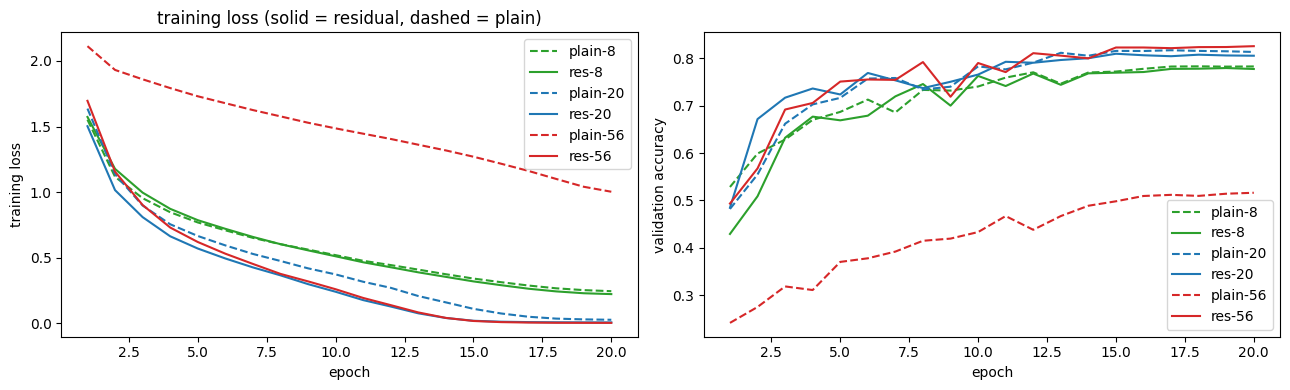

,final train loss,final val acc
plain-8,0.244522,0.7830
res-8,0.222267,0.7776
plain-20,0.026584,0.8136
res-20,0.006491,0.8056
plain-56,1.002734,0.5162
res-56,0.002878,0.8258


In [26]:
colors = {8: 'tab:green', 20: 'tab:blue', 56: 'tab:red'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (fam, d), h in res3b.items():
    ax[0].plot(range(1, EPOCHS_3B + 1), h['train_loss'], '-' if fam == 'res' else '--', color=colors[d], label=f'{fam}-{d}')
    ax[1].plot(range(1, EPOCHS_3B + 1), h['val_acc'], '-' if fam == 'res' else '--', color=colors[d], label=f'{fam}-{d}')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('training loss'); ax[0].set_title('training loss (solid = residual, dashed = plain)'); ax[0].legend()
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()
pd.DataFrame({f'{f}-{d}': {'final train loss': h['train_loss'][-1], 'final val acc': h['val_acc'][-1]} for (f, d), h in res3b.items()}).T

**Interpretation:** Training loss behaves very differently in the two families as depth grows. For plain networks, going from 20 to 56 layers makes training much worse. Plain-56 reaches a training loss of 1.00 after 20 epochs (and 51.6% validation accuracy), against 0.027 for plain-20, even though the deeper network could in principle represent the same function. This is the degradation problem: a deeper plain network is harder to optimise, and it is an optimisation failure, not overfitting, because the training loss itself is worse. Plain-8 and plain-20 train without trouble (0.245 and 0.027), so the problem appears only at large depth. For residual networks the trend is the opposite: training loss falls as depth increases (0.222 for res-8, 0.006 for res-20, 0.003 for res-56), and res-56 reaches 100% training accuracy by epoch 15. Res-56 also gives the best validation accuracy (82.6%). The identity shortcut gives gradients a direct path to early layers and lets each block learn only a correction to the identity, which makes very deep networks easy to optimise. Since the two families differ only in the shortcut, the improvement is attributable to it. Validation accuracy among the 8- and 20-layer networks is close (77.6–81.4%) and not clearly ordered, which is within run-to-run noise for a single seed.

# Task 4 (Optional): Best CNN with ≤ 500k parameters and ≤ 20 epochs
**Design:** residual CIFAR network with n = 3 (depth 20) widened to channels 20/40/80, SGD with Nesterov momentum, lr 0.1 with cosine decay, weight decay 5e-4, flip+crop augmentation, 20 epochs. All design choices are compared on the **validation split**: the test set is used only once, at the very end.

In [27]:
EPOCHS_4 = 20
def run_cfg(residual=True, aug=flip_crop, wd=5e-4, opt='sgd'):
    set_seed(0)
    model = CifarNet(3, residual, widths=(20, 40, 80)).to(device)
    assert sum(p.numel() for p in model.parameters()) < 500_000
    if opt == 'sgd': o = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
    else:            o = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(o, EPOCHS_4)
    h = train(model, o, EPOCHS_4, Xtr, Ytr, Xva, Yva, aug=aug, sched=sched)
    return model, h

print('parameters:', sum(p.numel() for p in CifarNet(3, True, widths=(20, 40, 80)).parameters()))
ablations = {'full model': {},
             'no shortcut (plain)': dict(residual=False),
             'no augmentation': dict(aug=None),
             'no weight decay': dict(wd=0.0),
             'Adam instead of SGD': dict(opt='adam')}
res4 = {}
for name, kw in ablations.items():
    print(f'--- {name}')
    res4[name] = run_cfg(**kw)

parameters: 424910
--- full model
ep   1  loss 1.445  train 0.506  val 0.496
ep   5  loss 0.628  train 0.802  val 0.786
ep  10  loss 0.452  train 0.757  val 0.735
ep  15  loss 0.293  train 0.911  val 0.868
ep  20  loss 0.164  train 0.960  val 0.899
--- no shortcut (plain)
ep   1  loss 1.644  train 0.503  val 0.498
ep   5  loss 0.766  train 0.682  val 0.665
ep  10  loss 0.559  train 0.790  val 0.771
ep  15  loss 0.382  train 0.871  val 0.840
ep  20  loss 0.240  train 0.933  val 0.877
--- no augmentation
ep   1  loss 1.375  train 0.580  val 0.568
ep   5  loss 0.512  train 0.823  val 0.777
ep  10  loss 0.293  train 0.895  val 0.806
ep  15  loss 0.049  train 0.995  val 0.849
ep  20  loss 0.005  train 1.000  val 0.855
--- no weight decay
ep   1  loss 1.470  train 0.552  val 0.535
ep   5  loss 0.585  train 0.807  val 0.786
ep  10  loss 0.377  train 0.870  val 0.837
ep  15  loss 0.257  train 0.927  val 0.871
ep  20  loss 0.196  train 0.948  val 0.879
--- Adam instead of SGD
ep   1  loss 1.455

,final val acc (%),best val acc (%),final train loss
full model,89.88,89.88,0.164
no shortcut (plain),87.72,87.72,0.240
no augmentation,85.54,85.54,0.005
no weight decay,87.90,87.94,0.196
Adam instead of SGD,86.88,87.14,0.253


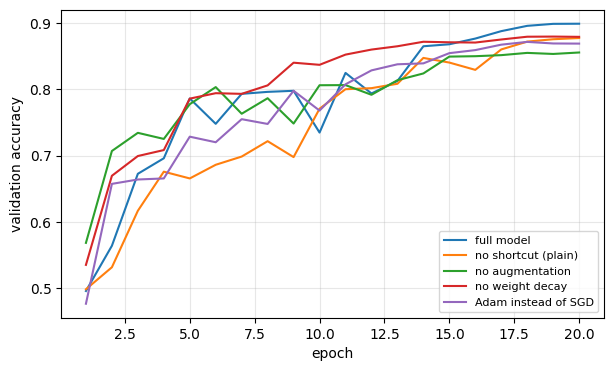

In [28]:
tab4 = pd.DataFrame({n: {'final val acc (%)': 100 * h['val_acc'][-1], 'best val acc (%)': 100 * max(h['val_acc']),
                         'final train loss': h['train_loss'][-1]} for n, (m, h) in res4.items()}).T
display(tab4.round(3))
plt.figure(figsize=(7, 4))
for n, (m, h) in res4.items(): plt.plot(range(1, EPOCHS_4 + 1), h['val_acc'], label=n)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

**Interpretation:** Each row changes one design choice relative to the full model (89.88% validation). Removing augmentation causes the largest drop (85.54%, −4.3 points): the network then memorises the training set (training loss 0.005) and generalises worse. Replacing SGD with Adam costs 3.0 points (86.88%), and removing the shortcut costs 2.2 points (87.72%), which confirms that residual connections help even at depth 20. Removing weight decay costs 2.0 points (87.90%). Each choice contributes, with augmentation mattering most. These are single runs with one seed, so differences of a few tenths of a point would be within noise, but the gaps here are larger than that. I chose the full model because it had the best validation accuracy.

In [29]:
# FINAL EVALUATION
best_name = max(res4, key=lambda n: res4[n][1]['val_acc'][-1])
best_model = res4[best_name][0]
test = torchvision.datasets.CIFAR10('./data', train=False, download=True)
Xte = ((torch.tensor(test.data).permute(0, 3, 1, 2).float() / 255 - mean) / std).to(device)
Yte = torch.tensor(test.targets).to(device)
_, test_acc = evaluate(best_model, Xte, Yte)
print(f'selected model: {best_name} | params: {sum(p.numel() for p in best_model.parameters())}')
print(f'validation accuracy: {res4[best_name][1]["val_acc"][-1]:.4f}')
print(f'TEST accuracy (evaluated once): {test_acc:.4f}')

selected model: full model | params: 424910
validation accuracy: 0.8988
TEST accuracy (evaluated once): 0.8995


**Final result:** The selected model (residual CIFAR-ResNet-20 widened to channels 20/40/80, 424,910 parameters, trained for 20 epochs with SGD + Nesterov momentum, cosine learning-rate decay, weight decay 5e-4 and flip+crop augmentation) reaches 89.95% test accuracy. This is very close to its validation accuracy (89.88%), so the model was not over-tuned to the validation split.